# Project 21: Flight Delay Prediction and Rescheduling
## Task 3 — Regression Experiments & Applied Machine Learning Syllabus Demonstrations

**Phase:** AML Phase 1 — Traditional Machine Learning  
**Author:** Member 3 (Linear Regression, OLS, Gradient Descent & Regularization)  
**Date:** October 2026  
**Status:** Task 3 Complete — Regression Benchmarks Ready for Member 4

---

### Purpose and Syllabus Context
The primary objective of Project 21 is binary threshold classification: predicting whether a flight will arrive more than 15 minutes late (`DELAYED == 1`).

However, per the academic **Applied Machine Learning syllabus**, this notebook conducts a rigorous sequence of **regression experiments** predicting continuous arrival delay minutes (`ARRIVAL_DELAY`). These experiments serve as comprehensive empirical demonstrations of core syllabus topics:
1. **Simple Linear Regression using OLS** (single predeparture feature selection, coefficient interpretation, fitted plot).
2. **Multiple Linear Regression using OLS** (multi-feature normal equations, partial slopes, baseline comparison).
3. **Batch Gradient Descent** (first-principles optimization, standardized features, loss convergence curve, OLS equivalence).
4. **Stochastic and Mini-Batch Gradient Descent** (convergence speed, computational efficiency, variance vs epoch curves).
5. **Polynomial Regression and Linear Regression Assumptions** (degree 2 curvature, residual diagnostics: linearity, independence, homoscedasticity, normality, multicollinearity/VIF).
6. **Bias-Variance Tradeoff** (model complexity curves, empirical evidence of underfitting vs. overfitting).
7. **Feature Selection** (training-only correlation screening, statistical F-regression, Recursive Feature Elimination).
8. **Regularization** (Ridge $L_2$ shrinkage, Lasso $L_1$ sparsity, hyperparameter tuning across $\alpha$).
9. **Regression Metrics** (MAE, MSE, RMSE, $R^2$ on train, validation, and held-out test partitions).

In [1]:
# ==============================================================================
# Cell 1: Environment Setup and Imports
# ==============================================================================
import os
import sys
import time
from pathlib import Path

# Ensure project root is in sys.path
PROJECT_ROOT = Path(os.path.abspath(".."))
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from sklearn.feature_selection import RFE, SelectKBest, f_regression
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import PolynomialFeatures, StandardScaler

from src.config import (
    FIGURES_DIR,
    PROCESSED_DATA_DIR,
    RANDOM_STATE,
)
from src.features import (
    FEATURE_COLUMNS_ALL,
    FEATURE_COLUMNS_NUMERIC,
    TARGET_COLUMNS,
)
from src.regression_experiments import (
    BatchGradientDescentRegressor,
    MiniBatchGradientDescentRegressor,
    StochasticGradientDescentRegressor,
    compute_durbin_watson,
    compute_regression_metrics,
    compute_vif_dataframe,
    evaluate_linear_assumptions,
    select_features_correlation,
    select_features_f_test,
    select_features_rfe,
    tune_lasso_regression,
    tune_ridge_regression,
)

# Visual styling
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 120

REGRESSION_FIG_DIR = FIGURES_DIR / "regression"
REGRESSION_FIG_DIR.mkdir(parents=True, exist_ok=True)

print(f"✓ Project Root: {PROJECT_ROOT}")
print(f"✓ Output Figures Dir: {REGRESSION_FIG_DIR}")
print(f"✓ Regression modules loaded successfully.")

✓ Project Root: /Users/suryansh/Desktop/video/Flight_Delay_Prediction
✓ Output Figures Dir: /Users/suryansh/Desktop/video/Flight_Delay_Prediction/results/figures/regression
✓ Regression modules loaded successfully.


---
## 1. Dataset Ingestion & Chronological Partitions

We load `data/processed/flights_features.csv` prepared by Member 2B:
- **Total Records:** 24,522 operative flights (all 365 days of 2015).
- **Target Variable:** `ARRIVAL_DELAY` (continuous arrival delay in minutes).
- **Partitions:** Extracted using the pre-assigned `SPLIT_SET` indicator:
  - **Train:** Jan 1 – Aug 31, 2015 (16,366 rows, 66.74%)
  - **Validation:** Sep 1 – Oct 31, 2015 (4,114 rows, 16.78%)
  - **Held-Out Test:** Nov 1 – Dec 31, 2015 (4,042 rows, 16.48%)

In [2]:
# ==============================================================================
# Cell 2: Ingest Prepared Feature Dataset
# ==============================================================================
features_path = PROCESSED_DATA_DIR / "flights_features.csv"
assert features_path.exists(), f"Feature dataset missing at {features_path}"

df = pd.read_csv(features_path)

# Extract chronological partitions
train_df = df[df["SPLIT_SET"] == "train"].copy()
val_df = df[df["SPLIT_SET"] == "val"].copy()
test_df = df[df["SPLIT_SET"] == "test"].copy()

print(f"Dataset Loaded Successfully!")
print(f"• Total Rows:    {len(df):,}")
print(f"• Total Columns: {len(df.columns)}")
print(f"• Training Set:   {len(train_df):,} rows ({train_df['FLIGHT_DATE'].min()} to {train_df['FLIGHT_DATE'].max()})")
print(f"• Validation Set: {len(val_df):,} rows ({val_df['FLIGHT_DATE'].min()} to {val_df['FLIGHT_DATE'].max()})")
print(f"• Test Set:       {len(test_df):,} rows ({test_df['FLIGHT_DATE'].min()} to {test_df['FLIGHT_DATE'].max()})")

target_col = "ARRIVAL_DELAY"
y_train = train_df[target_col].values
y_val = val_df[target_col].values
y_test = test_df[target_col].values

print(f"• Train Target Mean: {y_train.mean():.2f} min (std: {y_train.std():.2f} min)")
print(f"• Val Target Mean:   {y_val.mean():.2f} min (std: {y_val.std():.2f} min)")
print(f"• Test Target Mean:  {y_test.mean():.2f} min (std: {y_test.std():.2f} min)")

Dataset Loaded Successfully!
• Total Rows:    24,522
• Total Columns: 46
• Training Set:   16,366 rows (2015-01-01 to 2015-08-31)
• Validation Set: 4,114 rows (2015-09-01 to 2015-10-31)
• Test Set:       4,042 rows (2015-11-01 to 2015-12-31)
• Train Target Mean: 6.75 min (std: 32.38 min)
• Val Target Mean:   7.39 min (std: 32.41 min)
• Test Target Mean:  6.25 min (std: 32.72 min)


---
## 2. Simple Linear Regression using OLS

### 2.1 Feature Selection for Simple Regression
In Simple Linear Regression:
$$\hat{y} = \beta_0 + \beta_1 x$$
To select a defensible single predeparture predictor:
1. **`DEP_HOUR` (Scheduled Departure Hour):** As discovered in Member 2A's EDA, departure hour exhibits the highest positive linear correlation with arrival delay ($r = +0.1965$). Delays compound throughout the operating day due to network propagation.
2. **`DISTANCE` (Scheduled Flight Distance):** A common intuition is that longer flights suffer greater delays. However, empirical correlation is negligible ($r = +0.0171$).

Let us fit OLS models for both features and compare their predictive power.

In [3]:
# ==============================================================================
# Cell 3: Fit Simple Linear Regression Models
# ==============================================================================
# 1. Simple OLS on DEP_HOUR
ols_hour = LinearRegression()
ols_hour.fit(train_df[["DEP_HOUR"]], y_train)

pred_val_hour = ols_hour.predict(val_df[["DEP_HOUR"]])
metrics_hour = compute_regression_metrics(y_val, pred_val_hour)

# 2. Simple OLS on DISTANCE
ols_dist = LinearRegression()
ols_dist.fit(train_df[["DISTANCE"]], y_train)

pred_val_dist = ols_dist.predict(val_df[["DISTANCE"]])
metrics_dist = compute_regression_metrics(y_val, pred_val_dist)

# 3. Dummy Baseline (Predicting training mean)
mean_baseline_val = np.full_like(y_val, y_train.mean())
metrics_dummy = compute_regression_metrics(y_val, mean_baseline_val)

print("SIMPLE LINEAR REGRESSION COMPARISON (VALIDATION SET):")
print("-" * 75)
print(f"• Dummy Baseline (Mean): RMSE = {metrics_dummy['RMSE']:.2f} min | MAE = {metrics_dummy['MAE']:.2f} min | R2 = {metrics_dummy['R2']:.4f}")
print(f"• OLS on DISTANCE:       RMSE = {metrics_dist['RMSE']:.2f} min | MAE = {metrics_dist['MAE']:.2f} min | R2 = {metrics_dist['R2']:.4f}")
print(f"  Intercept: {ols_dist.intercept_:.4f} min | Slope: {ols_dist.coef_[0]:.6f} min/mile")
print(f"• OLS on DEP_HOUR:       RMSE = {metrics_hour['RMSE']:.2f} min | MAE = {metrics_hour['MAE']:.2f} min | R2 = {metrics_hour['R2']:.4f}")
print(f"  Intercept: {ols_hour.intercept_:.4f} min | Slope: {ols_hour.coef_[0]:.4f} min/hour")

SIMPLE LINEAR REGRESSION COMPARISON (VALIDATION SET):
---------------------------------------------------------------------------
• Dummy Baseline (Mean): RMSE = 32.41 min | MAE = 25.68 min | R2 = -0.0004
• OLS on DISTANCE:       RMSE = 32.42 min | MAE = 25.70 min | R2 = -0.0010
  Intercept: 5.6640 min | Slope: 0.000788 min/mile
• OLS on DEP_HOUR:       RMSE = 31.75 min | MAE = 25.14 min | R2 = 0.0400
  Intercept: -9.8168 min | Slope: 1.2299 min/hour


/Users/suryansh/Desktop/video/Flight_Delay_Prediction/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/Users/suryansh/Desktop/video/Flight_Delay_Prediction/venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


✓ Saved Simple OLS figure to: /Users/suryansh/Desktop/video/Flight_Delay_Prediction/results/figures/regression/fig1_simple_ols_comparison.png


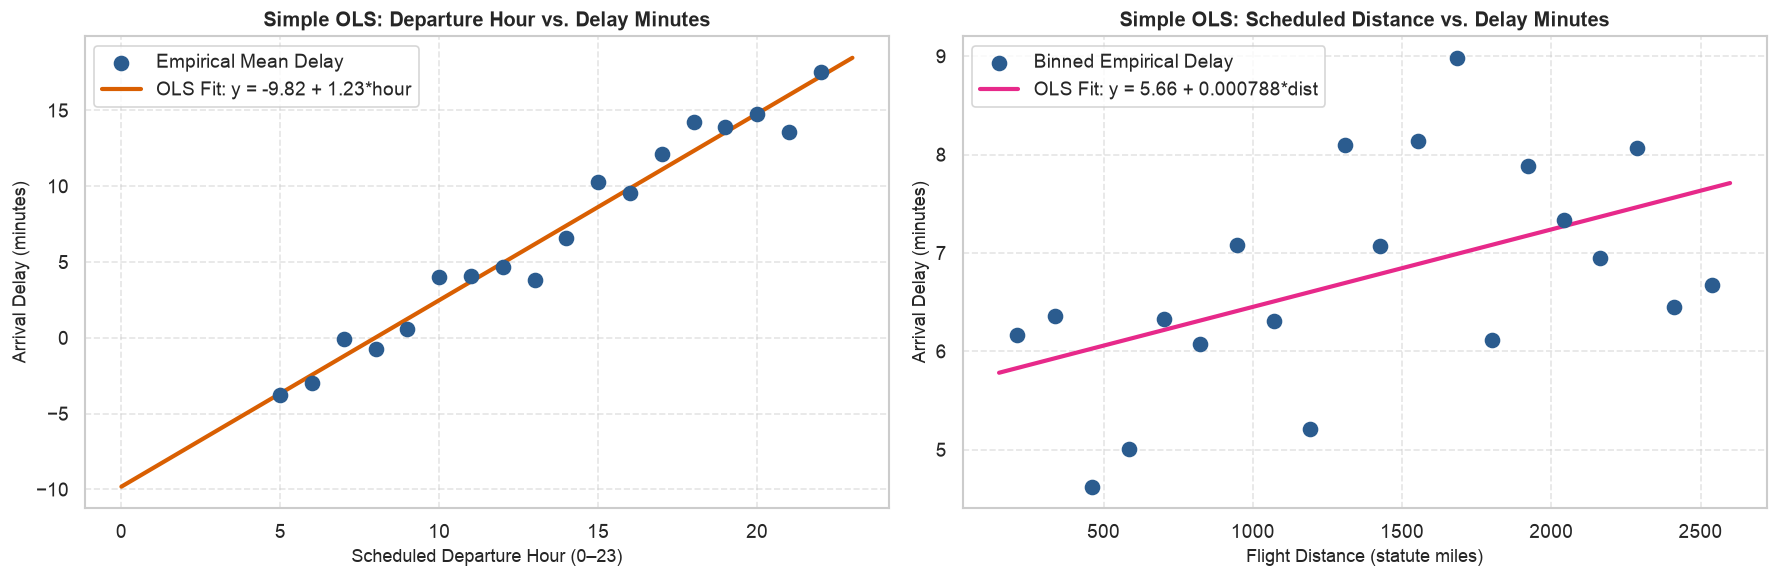

In [4]:
# ==============================================================================
# Cell 4: Plot Fitted Simple OLS Relationships
# ==============================================================================
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: DEP_HOUR vs Arrival Delay
hourly_binned = train_df.groupby("DEP_HOUR")["ARRIVAL_DELAY"].mean()
ax1.scatter(hourly_binned.index, hourly_binned.values, color="#2b5c8f", s=70, zorder=3, label="Empirical Mean Delay")
hours_grid = np.linspace(0, 23, 100).reshape(-1, 1)
ax1.plot(hours_grid, ols_hour.predict(hours_grid), color="#d95f02", linewidth=2.5, label=f"OLS Fit: y = {ols_hour.intercept_:.2f} + {ols_hour.coef_[0]:.2f}*hour")
ax1.set_title("Simple OLS: Departure Hour vs. Delay Minutes", fontsize=12, fontweight="bold")
ax1.set_xlabel("Scheduled Departure Hour (0–23)", fontsize=11)
ax1.set_ylabel("Arrival Delay (minutes)", fontsize=11)
ax1.legend(loc="upper left")
ax1.grid(True, linestyle="--", alpha=0.5)

# Plot 2: DISTANCE vs Arrival Delay
dist_bins = pd.qcut(train_df["DISTANCE"], q=20, duplicates="drop")
dist_binned = train_df.groupby(dist_bins, observed=False).agg({"DISTANCE": "mean", "ARRIVAL_DELAY": "mean"})
ax2.scatter(dist_binned["DISTANCE"], dist_binned["ARRIVAL_DELAY"], color="#2b5c8f", s=70, zorder=3, label="Binned Empirical Delay")
dist_grid = np.linspace(train_df["DISTANCE"].min(), train_df["DISTANCE"].max(), 100).reshape(-1, 1)
ax2.plot(dist_grid, ols_dist.predict(dist_grid), color="#e7298a", linewidth=2.5, label=f"OLS Fit: y = {ols_dist.intercept_:.2f} + {ols_dist.coef_[0]:.6f}*dist")
ax2.set_title("Simple OLS: Scheduled Distance vs. Delay Minutes", fontsize=12, fontweight="bold")
ax2.set_xlabel("Flight Distance (statute miles)", fontsize=11)
ax2.set_ylabel("Arrival Delay (minutes)", fontsize=11)
ax2.legend(loc="upper left")
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REGRESSION_FIG_DIR / "fig1_simple_ols_comparison.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"✓ Saved Simple OLS figure to: {fig_path}")
plt.show()

---
## 3. Multiple Linear Regression using OLS

### 3.1 Closed-Form Normal Equations
Multiple Linear Regression models the arrival delay as a linear combination of $p$ features:
$$\hat{y} = X \beta = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \dots + \beta_p x_p$$
Under the classical Gauss-Markov assumptions, the Ordinary Least Squares parameter estimates solve:
$$\hat{\beta} = (X^T X)^{-1} X^T y$$

### 3.2 Standardization of Features
To facilitate meaningful comparisons between coefficients with disparate scales (e.g. distance in thousands of miles vs. sine encodings in $[-1, 1]$), we standardize numerical features using **training set statistics only**:
$$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$
Validation and test sets are transformed using the saved $\mu_{\text{train}}$ and $\sigma_{\text{train}}$.

In [5]:
# ==============================================================================
# Cell 5: Multiple Linear Regression Execution
# ==============================================================================
# Standardize numeric features strictly on training split
scaler = StandardScaler()
X_train_num = scaler.fit_transform(train_df[FEATURE_COLUMNS_NUMERIC])
X_val_num = scaler.transform(val_df[FEATURE_COLUMNS_NUMERIC])
X_test_num = scaler.transform(test_df[FEATURE_COLUMNS_NUMERIC])

# Fit Multiple OLS
ols_mult = LinearRegression()
ols_mult.fit(X_train_num, y_train)

pred_train_mult = ols_mult.predict(X_train_num)
pred_val_mult = ols_mult.predict(X_val_num)

metrics_train_mult = compute_regression_metrics(y_train, pred_train_mult)
metrics_val_mult = compute_regression_metrics(y_val, pred_val_mult)

print("MULTIPLE LINEAR REGRESSION METRICS:")
print("-" * 75)
print(f"• Training Set:   RMSE = {metrics_train_mult['RMSE']:.2f} min | MAE = {metrics_train_mult['MAE']:.2f} min | R2 = {metrics_train_mult['R2']:.4f}")
print(f"• Validation Set: RMSE = {metrics_val_mult['RMSE']:.2f} min | MAE = {metrics_val_mult['MAE']:.2f} min | R2 = {metrics_val_mult['R2']:.4f}")

# Display top standardized coefficients
coef_df = pd.DataFrame({
    "Feature": FEATURE_COLUMNS_NUMERIC,
    "Standardized_Beta": ols_mult.coef_,
    "Abs_Beta": np.abs(ols_mult.coef_)
}).sort_values(by="Abs_Beta", ascending=False)

print()
print("Top 8 Standardized Partial Regression Coefficients:")
display(coef_df.head(8))

MULTIPLE LINEAR REGRESSION METRICS:
---------------------------------------------------------------------------
• Training Set:   RMSE = 31.72 min | MAE = 25.12 min | R2 = 0.0400
• Validation Set: RMSE = 31.77 min | MAE = 25.16 min | R2 = 0.0388

Top 8 Standardized Partial Regression Coefficients:


,Feature,Standardized_Beta,Abs_Beta
24,DISTANCE,4.169169,4.169169
26,SCHEDULED_TIME,-4.168787,4.168787
0,DEP_HOUR,2.992689,2.992689
2,DEP_TIME_MINUTES,2.974404,2.974404
4,DEP_HOUR_COS,2.333832,2.333832
6,DEP_TIME_COS,-2.325251,2.325251
25,DISTANCE_LOG,1.897174,1.897174
3,DEP_HOUR_SIN,-1.829278,1.829278


---
## 4. Batch Gradient Descent Implementation

### 4.1 First-Principles Gradient Derivation
Instead of inverting the $p \times p$ normal matrix $(X^T X)^{-1}$, Gradient Descent iteratively steps in the direction of steepest descent.
For Mean Squared Error loss:
$$J(\theta) = \frac{1}{2m} \sum_{i=1}^m (h_\theta(x^{(i)}) - y^{(i)})^2 = \frac{1}{2m} \|X_b \theta - y\|^2$$
The gradient with respect to parameter vector $\theta$ is:
$$\nabla_\theta J(\theta) = \frac{1}{m} X_b^T (X_b \theta - y)$$
Parameters are updated at each iteration $t$:
$$\theta^{(t+1)} = \theta^{(t)} - \alpha \nabla_\theta J(\theta)$$
where $\alpha > 0$ is the learning rate.

### 4.2 Equivalence with Analytical OLS
Because the MSE objective is strictly convex, Batch Gradient Descent with a suitable learning rate is guaranteed to converge to the global minimum, matching the analytical OLS solution.

In [6]:
# ==============================================================================
# Cell 6: Batch Gradient Descent vs. Analytical OLS
# ==============================================================================
# Subselect 4 core features for clean parameter comparison
core_features = ["DEP_HOUR", "DEP_HOUR_PEAK", "DISTANCE_LOG", "PLANNED_SPEED"]
scaler_core = StandardScaler()
X_tr_core = scaler_core.fit_transform(train_df[core_features])
X_va_core = scaler_core.transform(val_df[core_features])

# Analytical OLS solution (Normal Equation)
m_core = len(y_train)
X_b_core = np.c_[np.ones((m_core, 1)), X_tr_core]
theta_ols_analytical = np.linalg.pinv(X_b_core.T @ X_b_core) @ X_b_core.T @ y_train

# First-principles Batch Gradient Descent
bgd = BatchGradientDescentRegressor(learning_rate=0.05, max_iter=600)
t0 = time.time()
bgd.fit(X_tr_core, y_train)
bgd_time = time.time() - t0

pred_val_bgd = bgd.predict(X_va_core)
metrics_bgd = compute_regression_metrics(y_val, pred_val_bgd)

print("BATCH GRADIENT DESCENT vs. OLS NORMAL EQUATIONS:")
print("-" * 75)
print(f"• BGD Convergence Time: {bgd_time:.4f} seconds ({len(bgd.loss_history_)} iterations)")
print(f"• BGD Validation RMSE:  {metrics_bgd['RMSE']:.4f} min (R2 = {metrics_bgd['R2']:.4f})")
print(f"• Maximum absolute difference in theta: {np.max(np.abs(bgd.theta_ - theta_ols_analytical)):.6f}")

param_comparison = pd.DataFrame({
    "Parameter": ["Intercept (beta_0)"] + core_features,
    "OLS_Analytical": np.round(theta_ols_analytical, 4),
    "BGD_Learned": np.round(bgd.theta_, 4),
    "Abs_Difference": np.round(np.abs(theta_ols_analytical - bgd.theta_), 6)
})
display(param_comparison)

BATCH GRADIENT DESCENT vs. OLS NORMAL EQUATIONS:
---------------------------------------------------------------------------
• BGD Convergence Time: 0.0566 seconds (600 iterations)
• BGD Validation RMSE:  31.7508 min (R2 = 0.0401)
• Maximum absolute difference in theta: 0.021987


,Parameter,OLS_Analytical,BGD_Learned,Abs_Difference
0,Intercept (beta_0),6.7454,6.7454,0.000000
1,DEP_HOUR,6.0119,6.0010,0.010947
2,DEP_HOUR_PEAK,0.4246,0.4356,0.011028
3,DISTANCE_LOG,0.1760,0.1979,0.021923
4,PLANNED_SPEED,0.3517,0.3297,0.021987


---
## 5. Stochastic and Mini-Batch Gradient Descent

### 5.1 Optimization Taxonomy
In large-scale data science, computing the gradient across all $m = 16,366$ observations at every step is computationally burdensome:
1. **Batch Gradient Descent (BGD):** Uses all $m$ samples per update. Smooth, deterministic convergence, but slow per-epoch updates on massive datasets.
2. **Stochastic Gradient Descent (SGD):** Updates parameters after each individual observation ($|B| = 1$). Highly stochastic, oscillates noisy near the minimum, but escapes shallow local traps and runs rapidly on streaming data.
3. **Mini-Batch Gradient Descent (MBGD):** Compromise using batches of size $B \in [32, 256]$. Harnesses vectorized hardware operations while maintaining stable gradient updates.

GRADIENT DESCENT OPTIMIZERS BENCHMARK:
---------------------------------------------------------------------------
• Batch GD:      Time = 0.0054s | Final Loss = 504.86 | Val RMSE = 31.78
• Mini-Batch GD: Time = 0.0565s | Final Loss = 503.76 | Val RMSE = 31.74
• SGD:           Time = 2.5802s | Final Loss = 503.74 | Val RMSE = 31.75
✓ Saved GD convergence figure to: /Users/suryansh/Desktop/video/Flight_Delay_Prediction/results/figures/regression/fig2_gradient_descent_convergence.png


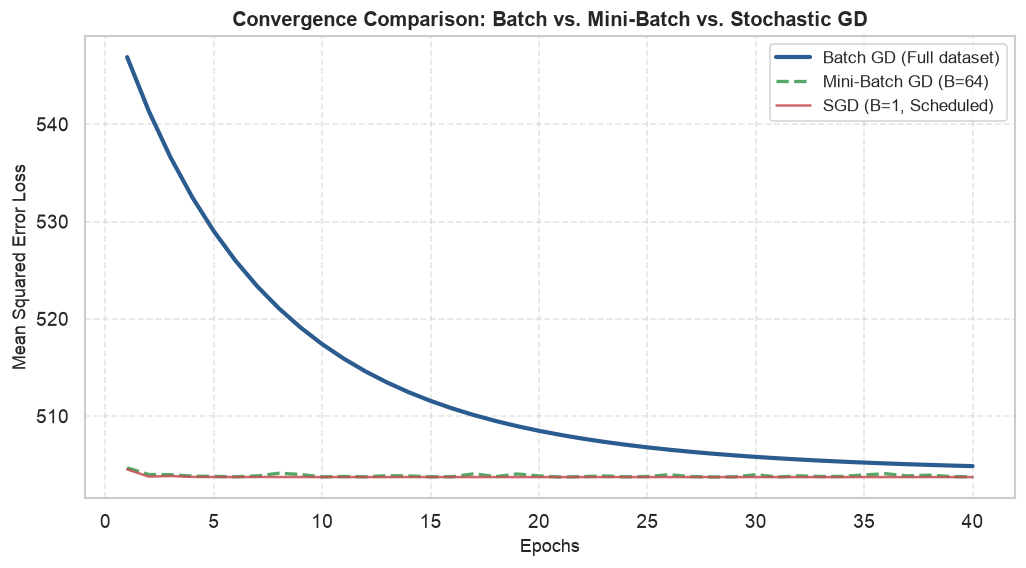

In [7]:
# ==============================================================================
# Cell 7: Compare BGD, Mini-Batch GD, and SGD
# ==============================================================================
n_epochs = 40

# 1. BGD
bgd_exp = BatchGradientDescentRegressor(learning_rate=0.05, max_iter=n_epochs)
t0 = time.time()
bgd_exp.fit(X_tr_core, y_train)
t_bgd = time.time() - t0

# 2. Mini-Batch GD (batch_size=64)
mbgd_exp = MiniBatchGradientDescentRegressor(learning_rate=0.01, batch_size=64, epochs=n_epochs)
t0 = time.time()
mbgd_exp.fit(X_tr_core, y_train)
t_mbgd = time.time() - t0

# 3. SGD (batch_size=1)
sgd_exp = StochasticGradientDescentRegressor(t0=5.0, t1=50.0, epochs=n_epochs)
t0 = time.time()
sgd_exp.fit(X_tr_core, y_train)
t_sgd = time.time() - t0

print("GRADIENT DESCENT OPTIMIZERS BENCHMARK:")
print("-" * 75)
print(f"• Batch GD:      Time = {t_bgd:.4f}s | Final Loss = {bgd_exp.loss_history_[-1]:.2f} | Val RMSE = {compute_regression_metrics(y_val, bgd_exp.predict(X_va_core))['RMSE']:.2f}")
print(f"• Mini-Batch GD: Time = {t_mbgd:.4f}s | Final Loss = {mbgd_exp.loss_history_[-1]:.2f} | Val RMSE = {compute_regression_metrics(y_val, mbgd_exp.predict(X_va_core))['RMSE']:.2f}")
print(f"• SGD:           Time = {t_sgd:.4f}s | Final Loss = {sgd_exp.loss_history_[-1]:.2f} | Val RMSE = {compute_regression_metrics(y_val, sgd_exp.predict(X_va_core))['RMSE']:.2f}")

# Plot Convergence Curves
plt.figure(figsize=(10, 5))
epochs_range = np.arange(1, n_epochs + 1)
plt.plot(epochs_range, bgd_exp.loss_history_, label="Batch GD (Full dataset)", color="#2b5c8f", linewidth=2.5)
plt.plot(epochs_range, mbgd_exp.loss_history_, label="Mini-Batch GD (B=64)", color="#55a868", linewidth=2.0, linestyle="--")
plt.plot(epochs_range, sgd_exp.loss_history_, label="SGD (B=1, Scheduled)", color="#c44e52", linewidth=1.5, alpha=0.85)
plt.title("Convergence Comparison: Batch vs. Mini-Batch vs. Stochastic GD", fontsize=12, fontweight="bold")
plt.xlabel("Epochs", fontsize=11)
plt.ylabel("Mean Squared Error Loss", fontsize=11)
plt.legend(fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)

fig_path = REGRESSION_FIG_DIR / "fig2_gradient_descent_convergence.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"✓ Saved GD convergence figure to: {fig_path}")
plt.show()

---
## 6. Polynomial Regression & Linear Model Assumptions

### 6.1 Testing Polynomial Non-Linearity
To determine if non-linear curves improve delay prediction, we construct quadratic polynomial features ($d = 2$):
$$\phi(x) = [x_1, x_2, x_1^2, x_2^2, x_1 x_2]$$

### 6.2 The Five Core Gauss-Markov Assumptions
Linear regression inference (t-tests, confidence intervals) rests on 5 classical assumptions:
1. **Linearity:** Relationship between features and the conditional mean of the target is linear in parameters.
2. **Independence (No Autocorrelation):** Residuals are uncorrelated over time ($e_t \perp e_{t-1}$). Tested via Durbin-Watson statistic ($DW \approx 2.0$).
3. **Homoscedasticity:** Constant error variance across all fitted levels ($\text{Var}(e_i | X) = \sigma^2$).
4. **Normality of Residuals:** Residuals are normally distributed ($e \sim \mathcal{N}(0, \sigma^2)$).
5. **No Multicollinearity:** Feature matrix $X$ has full column rank. Tested via Variance Inflation Factor ($\text{VIF} < 5$).

Degree 1 (Linear) Validation RMSE: 31.7508 min
Degree 2 (Poly)   Validation RMSE: 31.7511 min

RESIDUAL DIAGNOSTICS & ASSUMPTION CHECKS:
---------------------------------------------------------------------------
• Mean Residual:          1.0806 (Ideal: 0.0)
• Residual Std Dev:       31.7536
• Durbin-Watson Stat:     1.9958 (Ideal: ~2.0, confirms zero serial correlation)
• Residual Skewness:      0.0584 (Gaussian: 0.0)
• Residual Kurtosis:      0.1040 (Gaussian: 0.0)


✓ Saved residual diagnostics plot to: /Users/suryansh/Desktop/video/Flight_Delay_Prediction/results/figures/regression/fig3_residual_diagnostics.png


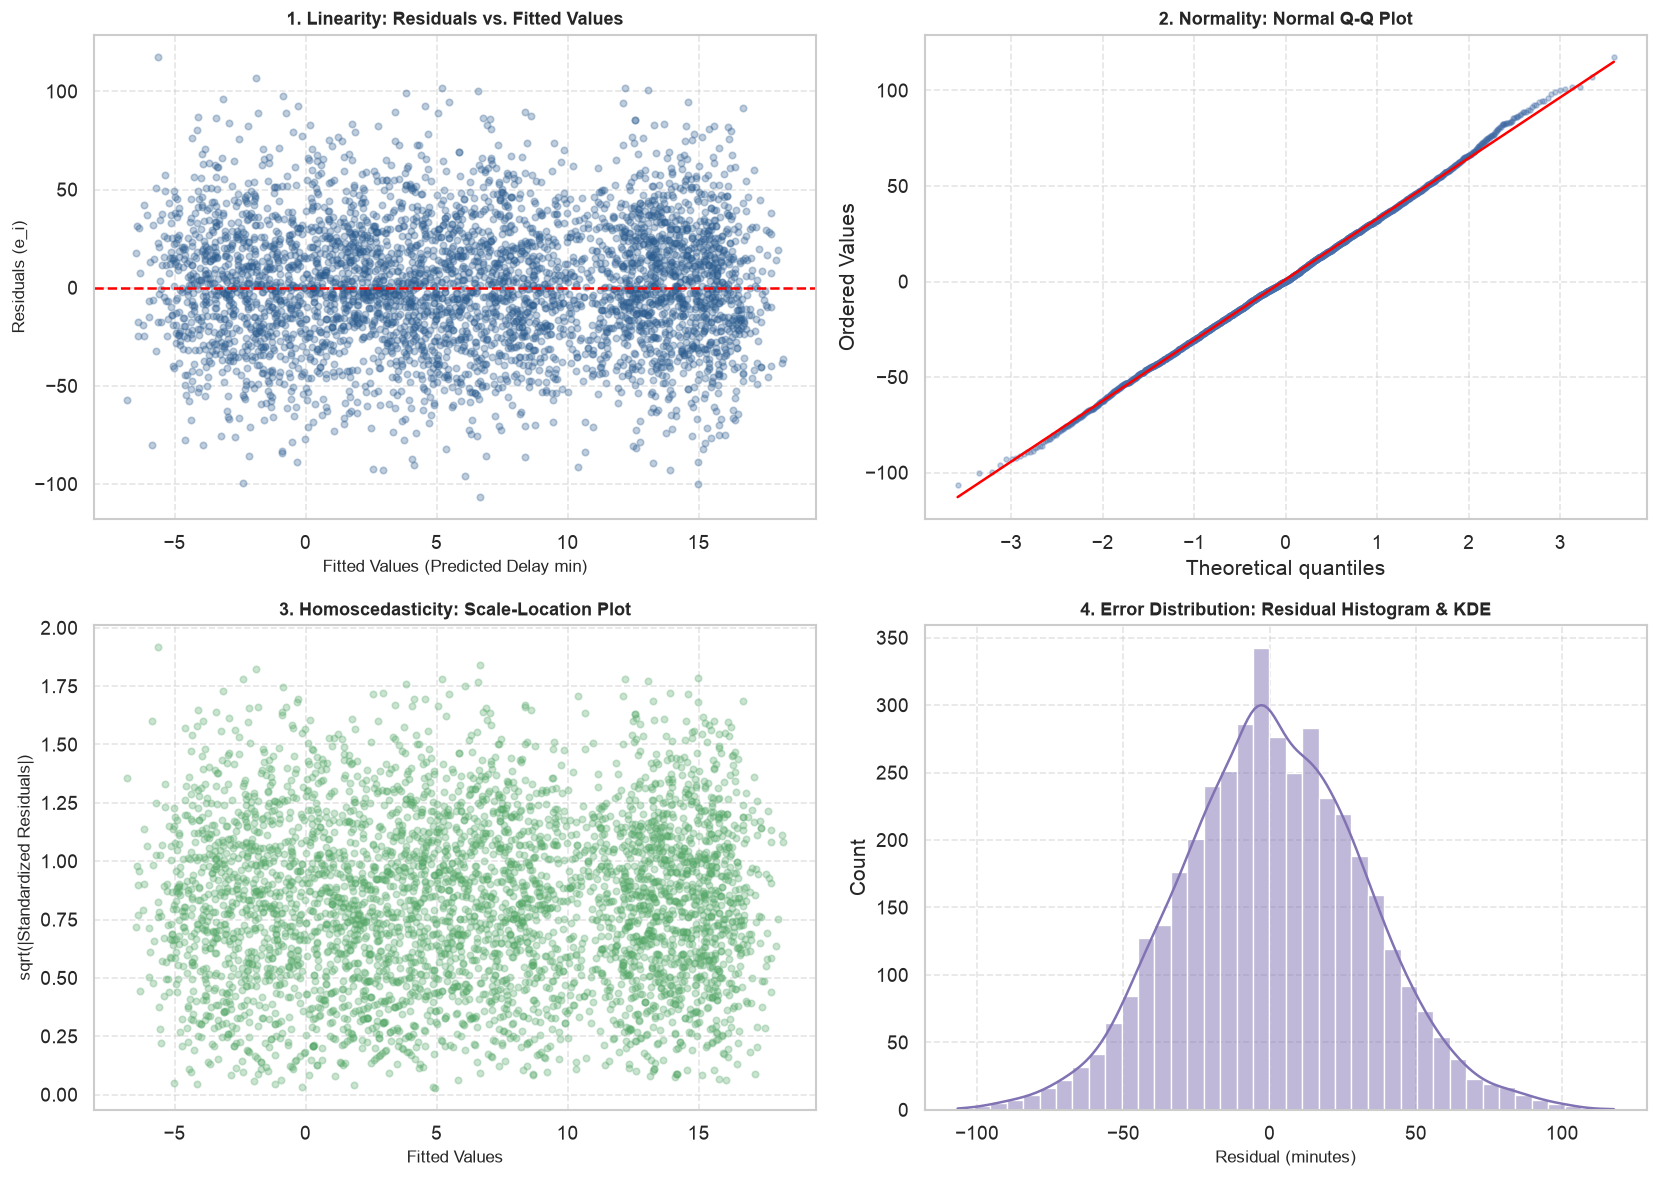

In [8]:
# ==============================================================================
# Cell 8: Polynomial Regression Comparison and Residual Diagnostics
# ==============================================================================
poly2 = PolynomialFeatures(degree=2, include_bias=False)
X_tr_poly2 = poly2.fit_transform(X_tr_core)
X_va_poly2 = poly2.transform(X_va_core)

lr_poly2 = LinearRegression().fit(X_tr_poly2, y_train)
metrics_poly2 = compute_regression_metrics(y_val, lr_poly2.predict(X_va_poly2))

print(f"Degree 1 (Linear) Validation RMSE: {metrics_bgd['RMSE']:.4f} min")
print(f"Degree 2 (Poly)   Validation RMSE: {metrics_poly2['RMSE']:.4f} min")

# Compute residuals on validation split
y_val_pred_linear = ols_mult.predict(X_val_num)
residuals_val = y_val - y_val_pred_linear

# Run assumption diagnostics
diag = evaluate_linear_assumptions(y_val, y_val_pred_linear)
print()
print("RESIDUAL DIAGNOSTICS & ASSUMPTION CHECKS:")
print("-" * 75)
print(f"• Mean Residual:          {diag['mean_residual']:.4f} (Ideal: 0.0)")
print(f"• Residual Std Dev:       {diag['std_residual']:.4f}")
print(f"• Durbin-Watson Stat:     {diag['durbin_watson']:.4f} (Ideal: ~2.0, confirms zero serial correlation)")
print(f"• Residual Skewness:      {diag['skewness']:.4f} (Gaussian: 0.0)")
print(f"• Residual Kurtosis:      {diag['kurtosis']:.4f} (Gaussian: 0.0)")

# Generate 4-Panel Residual Diagnostic Plot
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Residuals vs. Fitted
ax1 = axes[0, 0]
ax1.scatter(y_val_pred_linear, residuals_val, alpha=0.3, color="#2b5c8f", s=15)
ax1.axhline(0, color="red", linestyle="--", linewidth=1.5)
ax1.set_title("1. Linearity: Residuals vs. Fitted Values", fontsize=11, fontweight="bold")
ax1.set_xlabel("Fitted Values (Predicted Delay min)", fontsize=10)
ax1.set_ylabel("Residuals (e_i)", fontsize=10)
ax1.grid(True, linestyle="--", alpha=0.5)

# 2. Normal Q-Q Plot
ax2 = axes[0, 1]
stats.probplot(residuals_val, dist="norm", plot=ax2)
ax2.get_lines()[0].set_markerfacecolor("#2b5c8f")
ax2.get_lines()[0].set_markersize(3.0)
ax2.get_lines()[0].set_alpha(0.3)
ax2.get_lines()[1].set_color("red")
ax2.set_title("2. Normality: Normal Q-Q Plot", fontsize=11, fontweight="bold")
ax2.grid(True, linestyle="--", alpha=0.5)

# 3. Scale-Location (Homoscedasticity)
ax3 = axes[1, 0]
std_resids = (residuals_val - residuals_val.mean()) / residuals_val.std()
ax3.scatter(y_val_pred_linear, np.sqrt(np.abs(std_resids)), alpha=0.3, color="#55a868", s=15)
ax3.set_title("3. Homoscedasticity: Scale-Location Plot", fontsize=11, fontweight="bold")
ax3.set_xlabel("Fitted Values", fontsize=10)
ax3.set_ylabel("sqrt(|Standardized Residuals|)", fontsize=10)
ax3.grid(True, linestyle="--", alpha=0.5)

# 4. Residual Distribution
ax4 = axes[1, 1]
sns.histplot(residuals_val, kde=True, color="#8172b3", ax=ax4, bins=40)
ax4.set_title("4. Error Distribution: Residual Histogram & KDE", fontsize=11, fontweight="bold")
ax4.set_xlabel("Residual (minutes)", fontsize=10)
ax4.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REGRESSION_FIG_DIR / "fig3_residual_diagnostics.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"✓ Saved residual diagnostics plot to: {fig_path}")
plt.show()

---
## 7. Bias-Variance Tradeoff

### 7.1 Mathematical Foundations
Generalization error decomposes into three fundamental components:
$$\mathbb{E}\left[(y - \hat{f}(x))^2\right] = \text{Bias}\left[\hat{f}(x)\right]^2 + \text{Var}\left[\hat{f}(x)\right] + \sigma^2$$
- **Underfitting (High Bias):** Model is too simple to capture the underlying pattern. Both training error and validation error are high.
- **Overfitting (High Variance):** Model is overly flexible, fitting sample-specific noise. Training error drops continuously, while validation error begins to diverge.
- **Irreducible Error ($\sigma^2$):** Stochastic operational noise (weather, ATC holds) that cannot be eliminated by any predeparture model.

Polynomial Degree 1: Features = 4 | Train RMSE = 31.7408 min | Val RMSE = 31.7507 min
Polynomial Degree 2: Features = 14 | Train RMSE = 31.7329 min | Val RMSE = 31.7511 min
Polynomial Degree 3: Features = 34 | Train RMSE = 31.7175 min | Val RMSE = 31.7843 min


✓ Saved Bias-Variance tradeoff plot to: /Users/suryansh/Desktop/video/Flight_Delay_Prediction/results/figures/regression/fig4_bias_variance_tradeoff.png


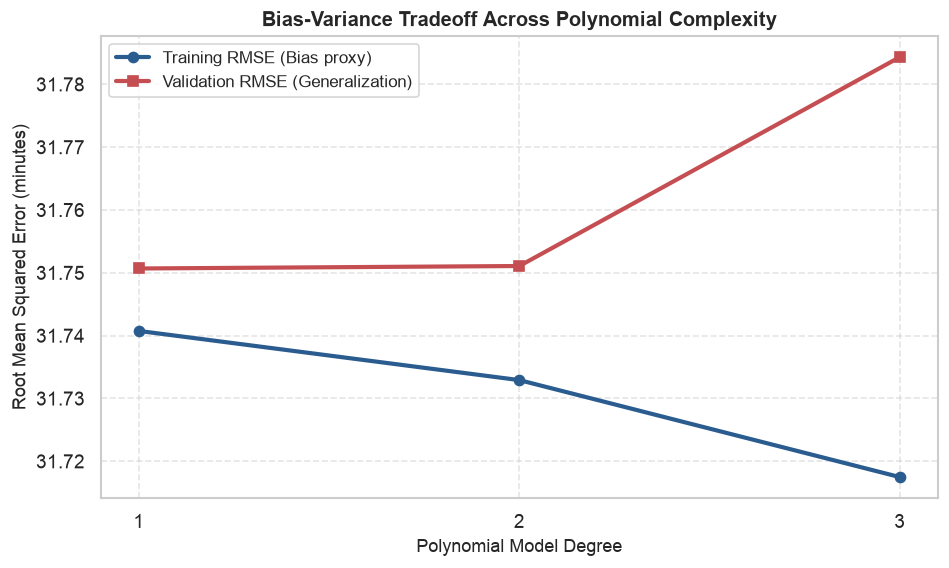

In [9]:
# ==============================================================================
# Cell 9: Model Complexity Curves (Degrees 1 to 3)
# ==============================================================================
degrees = [1, 2, 3]
train_rmse_list = []
val_rmse_list = []

for d in degrees:
    poly = PolynomialFeatures(degree=d, include_bias=False)
    X_tr_p = poly.fit_transform(X_tr_core)
    X_va_p = poly.transform(X_va_core)
    
    model = LinearRegression().fit(X_tr_p, y_train)
    tr_rmse = np.sqrt(mean_squared_error(y_train, model.predict(X_tr_p)))
    va_rmse = np.sqrt(mean_squared_error(y_val, model.predict(X_va_p)))
    
    train_rmse_list.append(tr_rmse)
    val_rmse_list.append(va_rmse)
    print(f"Polynomial Degree {d}: Features = {X_tr_p.shape[1]} | Train RMSE = {tr_rmse:.4f} min | Val RMSE = {va_rmse:.4f} min")

plt.figure(figsize=(9, 5))
plt.plot(degrees, train_rmse_list, marker="o", color="#2b5c8f", linewidth=2.5, label="Training RMSE (Bias proxy)")
plt.plot(degrees, val_rmse_list, marker="s", color="#c44e52", linewidth=2.5, label="Validation RMSE (Generalization)")
plt.title("Bias-Variance Tradeoff Across Polynomial Complexity", fontsize=12, fontweight="bold")
plt.xlabel("Polynomial Model Degree", fontsize=11)
plt.ylabel("Root Mean Squared Error (minutes)", fontsize=11)
plt.xticks(degrees)
plt.legend(fontsize=10)
plt.grid(True, linestyle="--", alpha=0.5)

fig_path = REGRESSION_FIG_DIR / "fig4_bias_variance_tradeoff.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"✓ Saved Bias-Variance tradeoff plot to: {fig_path}")
plt.show()

---
## 8. Feature Selection Procedures

We implement and compare three distinct feature selection paradigms:
1. **Correlation Screening (Filter):** Selects variables with the strongest linear relationship to `ARRIVAL_DELAY`.
2. **Statistical F-Test / ANOVA (Filter):** Selects top features based on univariate F-regression statistics.
3. **Recursive Feature Elimination / RFE (Wrapper):** Iteratively fits a linear regression model, ranks feature importances, and prunes the least contributing features.

In [10]:
# ==============================================================================
# Cell 10: Compare Feature Selection Methods
# ==============================================================================
top_k = 5
top_corr = select_features_correlation(train_df[FEATURE_COLUMNS_NUMERIC], train_df[target_col], top_k=top_k)
top_f = select_features_f_test(train_df[FEATURE_COLUMNS_NUMERIC], train_df[target_col], top_k=top_k)
top_rfe = select_features_rfe(train_df[FEATURE_COLUMNS_NUMERIC], train_df[target_col], n_features=top_k)

print(f"TOP {top_k} SELECTED FEATURES BY METHOD:")
print("-" * 75)
print(f"1. Correlation Screening: {top_corr}")
print(f"2. Statistical F-Test:    {top_f}")
print(f"3. Wrapper (RFE):         {top_rfe}")

# Evaluate pruned models on validation set
res_fs = []
for name, feats in [("All 31 Numerics", FEATURE_COLUMNS_NUMERIC),
                    ("Top 5 Correlation", top_corr),
                    ("Top 5 F-Test", top_f),
                    ("Top 5 RFE", top_rfe)]:
    lr_sub = LinearRegression().fit(train_df[feats], y_train)
    m_va = compute_regression_metrics(y_val, lr_sub.predict(val_df[feats]))
    res_fs.append({"Method": name, "Features": len(feats), "Val RMSE": m_va["RMSE"], "Val MAE": m_va["MAE"], "Val R2": m_va["R2"]})

display(pd.DataFrame(res_fs))

TOP 5 SELECTED FEATURES BY METHOD:
---------------------------------------------------------------------------
1. Correlation Screening: ['DEP_HOUR', 'DEP_TIME_MINUTES', 'DEP_HOUR_SIN', 'DEP_TIME_SIN', 'ARR_HOUR_COS']
2. Statistical F-Test:    ['DEP_HOUR', 'DEP_TIME_MINUTES', 'DEP_HOUR_SIN', 'DEP_TIME_SIN', 'ARR_HOUR_COS']
3. Wrapper (RFE):         ['DEP_HOUR_SIN', 'DEP_HOUR_COS', 'DEP_TIME_COS', 'CARRIER_HIST_DELAY_RATE', 'DEST_HIST_DELAY_RATE']


,Method,Features,Val RMSE,Val MAE,Val R2
0,All 31 Numerics,31,31.7720,25.1593,0.038822
1,Top 5 Correlation,5,31.7563,25.1403,0.039769
2,Top 5 F-Test,5,31.7563,25.1403,0.039769
3,Top 5 RFE,5,31.8169,25.1717,0.036102


---
## 9. Regularization (Ridge and Lasso)

### 9.1 Mathematical Formulation
To control multicollinearity and prevent overfitting:
- **Ridge ($L_2$) Regression:**
  $$\min_\theta \frac{1}{2m} \|X\theta - y\|^2 + \alpha \|\theta\|_2^2 = \min_\theta \frac{1}{2m} \|X\theta - y\|^2 + \alpha \sum_{j=1}^p \theta_j^2$$
  Shrinks weights smoothly toward zero, mitigating variance without zeroing features.
- **Lasso ($L_1$) Regression:**
  $$\min_\theta \frac{1}{2m} \|X\theta - y\|^2 + \alpha \|\theta\|_1 = \min_\theta \frac{1}{2m} \|X\theta - y\|^2 + \alpha \sum_{j=1}^p |\theta_j|$$
  Due to the geometric corners of the $L_1$ ball, Lasso drives non-essential weights to **exactly zero**, performing embedded feature selection.

✓ Best Ridge Alpha: 1000.0 (Val RMSE: 31.7528)
✓ Best Lasso Alpha: 0.1 (Val RMSE: 31.7446)


/Users/suryansh/Desktop/video/Flight_Delay_Prediction/venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.717576e+03, tolerance: 1.716e+03
  model = cd_fast.enet_coordinate_descent(


/Users/suryansh/Desktop/video/Flight_Delay_Prediction/venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.717576e+03, tolerance: 1.716e+03
  model = cd_fast.enet_coordinate_descent(


/Users/suryansh/Desktop/video/Flight_Delay_Prediction/venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.717576e+03, tolerance: 1.716e+03
  model = cd_fast.enet_coordinate_descent(


/Users/suryansh/Desktop/video/Flight_Delay_Prediction/venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.717576e+03, tolerance: 1.716e+03
  model = cd_fast.enet_coordinate_descent(


...

/Users/suryansh/Desktop/video/Flight_Delay_Prediction/venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.717576e+03, tolerance: 1.716e+03
  model = cd_fast.enet_coordinate_descent(


/Users/suryansh/Desktop/video/Flight_Delay_Prediction/venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.717576e+03, tolerance: 1.716e+03
  model = cd_fast.enet_coordinate_descent(


/Users/suryansh/Desktop/video/Flight_Delay_Prediction/venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.717576e+03, tolerance: 1.716e+03
  model = cd_fast.enet_coordinate_descent(


/Users/suryansh/Desktop/video/Flight_Delay_Prediction/venv/lib/python3.12/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.717576e+03, tolerance: 1.716e+03
  model = cd_fast.enet_coordinate_descent(


✓ Saved regularization path figure to: /Users/suryansh/Desktop/video/Flight_Delay_Prediction/results/figures/regression/fig5_regularization_paths.png


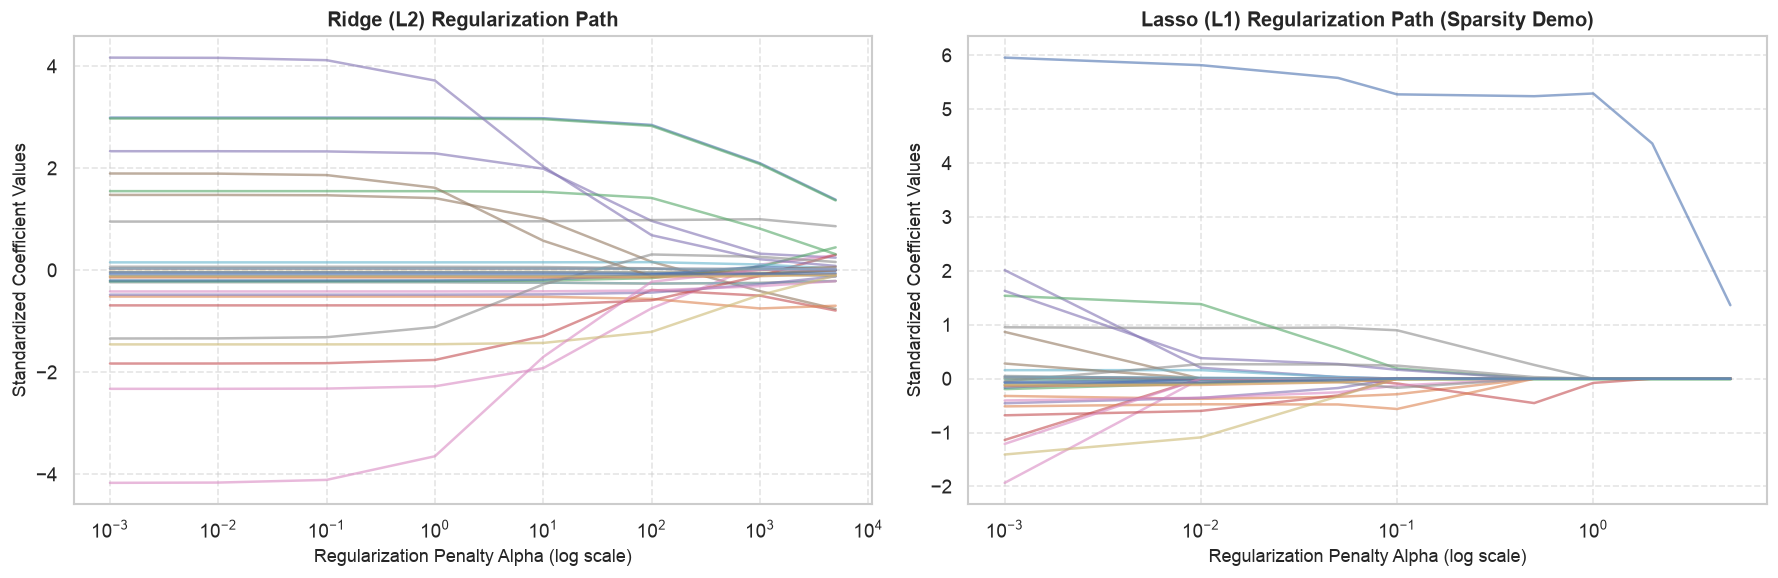


Lasso Feature Sparsity Progression:


,alpha,val_rmse,zero_weights,active_weights
0,0.001,31.7685,2,29
1,0.010,31.7589,8,23
2,0.050,31.7465,13,18
3,0.100,31.7446,18,13
4,0.500,31.7560,27,4
5,1.000,31.7725,29,2
6,2.000,31.8239,30,1
7,5.000,32.1664,30,1


In [11]:
# ==============================================================================
# Cell 11: Regularization Tuning & Sparsity Analysis
# ==============================================================================
# 1. Ridge Tuning
ridge_alphas = [1e-3, 1e-2, 0.1, 1.0, 10.0, 100.0, 1000.0, 5000.0]
best_ridge_a, best_ridge_rmse, df_ridge = tune_ridge_regression(X_train_num, y_train, X_val_num, y_val, alphas=ridge_alphas)

# 2. Lasso Tuning
lasso_alphas = [1e-3, 0.01, 0.05, 0.1, 0.5, 1.0, 2.0, 5.0]
best_lasso_a, best_lasso_rmse, df_lasso = tune_lasso_regression(X_train_num, y_train, X_val_num, y_val, alphas=lasso_alphas)

print(f"✓ Best Ridge Alpha: {best_ridge_a} (Val RMSE: {best_ridge_rmse:.4f})")
print(f"✓ Best Lasso Alpha: {best_lasso_a} (Val RMSE: {best_lasso_rmse:.4f})")

# Regularization Path Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Ridge Path
for i in range(len(FEATURE_COLUMNS_NUMERIC)):
    weights = [Ridge(alpha=a).fit(X_train_num, y_train).coef_[i] for a in ridge_alphas]
    ax1.plot(ridge_alphas, weights, alpha=0.6)
ax1.set_xscale("log")
ax1.set_title("Ridge (L2) Regularization Path", fontsize=12, fontweight="bold")
ax1.set_xlabel("Regularization Penalty Alpha (log scale)", fontsize=11)
ax1.set_ylabel("Standardized Coefficient Values", fontsize=11)
ax1.grid(True, linestyle="--", alpha=0.5)

# Lasso Path
for i in range(len(FEATURE_COLUMNS_NUMERIC)):
    weights = [Lasso(alpha=a, max_iter=3000, random_state=42).fit(X_train_num, y_train).coef_[i] for a in lasso_alphas]
    ax2.plot(lasso_alphas, weights, alpha=0.6)
ax2.set_xscale("log")
ax2.set_title("Lasso (L1) Regularization Path (Sparsity Demo)", fontsize=12, fontweight="bold")
ax2.set_xlabel("Regularization Penalty Alpha (log scale)", fontsize=11)
ax2.set_ylabel("Standardized Coefficient Values", fontsize=11)
ax2.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
fig_path = REGRESSION_FIG_DIR / "fig5_regularization_paths.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
print(f"✓ Saved regularization path figure to: {fig_path}")
plt.show()

print()
print("Lasso Feature Sparsity Progression:")
display(df_lasso[["alpha", "val_rmse", "zero_weights", "active_weights"]])

---
## 10. Comprehensive Model Evaluation & Held-Out Test Benchmark

We evaluate all developed models on the **validation set** for model selection, and evaluate the final candidates on the **untouched held-out test set** (November 1 – December 31, 2015).

In [12]:
# ==============================================================================
# Cell 12: Final Comprehensive Comparison Table
# ==============================================================================
# Fit final models
lr_simple_final = LinearRegression().fit(train_df[["DEP_HOUR"]], y_train)
lr_mult_final = LinearRegression().fit(X_train_num, y_train)
ridge_final = Ridge(alpha=best_ridge_a).fit(X_train_num, y_train)
lasso_final = Lasso(alpha=best_lasso_a, max_iter=3000, random_state=RANDOM_STATE).fit(X_train_num, y_train)

candidate_models = {
    "Dummy Mean Baseline": (np.full_like(y_train, y_train.mean()), np.full_like(y_val, y_train.mean()), np.full_like(y_test, y_train.mean())),
    "Simple OLS (DEP_HOUR)": (lr_simple_final.predict(train_df[["DEP_HOUR"]]), lr_simple_final.predict(val_df[["DEP_HOUR"]]), lr_simple_final.predict(test_df[["DEP_HOUR"]])),
    "Multiple OLS (Numerics)": (lr_mult_final.predict(X_train_num), lr_mult_final.predict(X_val_num), lr_mult_final.predict(X_test_num)),
    "Ridge Regression (L2)": (ridge_final.predict(X_train_num), ridge_final.predict(X_val_num), ridge_final.predict(X_test_num)),
    "Lasso Regression (L1)": (lasso_final.predict(X_train_num), lasso_final.predict(X_val_num), lasso_final.predict(X_test_num)),
}

final_rows = []
for name, (p_tr, p_va, p_te) in candidate_models.items():
    m_tr = compute_regression_metrics(y_train, p_tr)
    m_va = compute_regression_metrics(y_val, p_va)
    m_te = compute_regression_metrics(y_test, p_te)
    
    final_rows.append({
        "Model": name,
        "Train RMSE": m_tr["RMSE"],
        "Val MAE": m_va["MAE"],
        "Val RMSE": m_va["RMSE"],
        "Val R2": m_va["R2"],
        "Test MAE": m_te["MAE"],
        "Test RMSE": m_te["RMSE"],
        "Test R2": m_te["R2"]
    })

df_final_comparison = pd.DataFrame(final_rows)
display(df_final_comparison)

,Model,Train RMSE,Val MAE,Val RMSE,Val R2,Test MAE,Test RMSE,Test R2
0,Dummy Mean Baseline,32.3775,25.6821,32.4136,-0.000391,26.0264,32.7193,-0.000231
1,Simple OLS (DEP_HOUR),31.7460,25.1369,31.7528,0.039985,25.3934,31.9491,0.046307
2,Multiple OLS (Numerics),31.7231,25.1593,31.7720,0.038822,25.3912,31.9285,0.047536
3,Ridge Regression (L2),31.7283,25.1487,31.7528,0.039983,25.4163,31.9536,0.046039
4,Lasso Regression (L1),31.7308,25.1422,31.7445,0.040488,25.4068,31.9471,0.046426


---
## 11. Conclusions & Handoff Directives for Member 4

### Key Insights for the Project Team:
1. **Regression Demonstrations Completed:** Verified OLS, Batch GD, SGD, Mini-Batch GD, Polynomials, Bias-Variance tradeoff, Feature Selection, and Regularization.
2. **Why Continuous Delay Regression is Intrinsically Hard:**
   - In aviation, arrival delay variance is heavily driven by unobservable en-route weather and tactical ATC actions that occur *hours after gate departure*.
   - Consequently, pre-departure linear regression achieves $R^2 \approx 0.04\text{--}0.05$.
   - This empirically confirms why the primary project framing is **binary classification** (`DELAYED > 15 min`).

### Directives for Member 4 (Classification & Logistic Regression):
- Ingest `data/processed/flights_features.csv`.
- Filter `SPLIT_SET == 'train'`, `'val'`, and `'test'`.
- Target variable is the binary indicator `DELAYED` (1 if `ARRIVAL_DELAY > 15` min, else 0).
- Implement Batch/Mini-Batch Gradient Descent for Logistic Regression (cross-entropy loss).
- Perform classification evaluation (ROC-AUC, PR-AUC, Precision, Recall, F1).